# RQ1 — Đặc trưng đồ thị và điểm vận hành / Graph features and review budgets

**Trương Minh Hoàng · MSSV 25410008**

Tôi dùng ví dụ nhỏ để giải thích đúng hướng cạnh, cách gộp cạnh trùng và nút cô lập,
rồi đọc kết quả thực nghiệm đã khóa của KLTN. Ví dụ nhỏ không thay thế benchmark DGraphFin.

A hand-checkable graph demonstrates the thesis feature formula. The final table and chart
read saved historical results; this notebook does not retrain LightGBM on DGraphFin.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if not (PROJECT / 'shared_risk_context').is_dir():
    raise FileNotFoundError('Run from this project directory or its notebooks directory.')
sys.path.insert(0, str(PROJECT))
import numpy as np
import pandas as pd
from IPython.display import display

## 1. Đồ thị có hướng / Directed graph

Quy ước `A[source, destination] = 1`. Vì vậy `A @ x` tổng hợp thuộc tính
**láng giềng đi ra**. Đồ thị ví dụ có 5 nút, một cạnh trùng và một nút cô lập.
The five-node synthetic graph includes a duplicate edge and an isolated node.

In [2]:
from shared_risk_context.examples import graph_fixture
from shared_risk_context.graph_features import build_graph_features
x, edges, relation_types = graph_fixture()
graph_features = build_graph_features(x, edges, relation_types)
columns = ['log1p_in_degree', 'log1p_out_degree', 'reciprocal_ratio',
           'log1p_relation_diversity', 'out_mean_x0', 'out_mean_x1']
display(pd.DataFrame(graph_features, columns=columns).rename_axis('node'))
expected_means = np.array([[4,8],[1,2],[7,14],[5,10],[0,0]], dtype='float32')
np.testing.assert_allclose(graph_features[:, 4:], expected_means)
print('Hand-calculated outgoing means: PASS')

,log1p_in_degree,log1p_out_degree,reciprocal_ratio,log1p_relation_diversity,out_mean_x0,out_mean_x1
node,,,,,,
0,0.693147,1.098612,0.5,1.098612,4.0,8.0
1,0.693147,0.693147,1.0,0.693147,1.0,2.0
2,1.098612,0.693147,1.0,0.693147,7.0,14.0
3,0.693147,0.693147,1.0,0.693147,5.0,10.0
4,0.000000,0.000000,0.0,0.000000,0.0,0.0


Hand-calculated outgoing means: PASS


In [3]:
incoming_features = build_graph_features(x, edges[::-1], relation_types)
comparison = pd.DataFrame({'outgoing_mean_x0': graph_features[:, 4],
                           'incoming_mean_x0': incoming_features[:, 4]})
display(comparison)
assert graph_features[0, 4] == 4 and incoming_features[0, 4] == 3

,outgoing_mean_x0,incoming_mean_x0
0,4.0,3.0
1,1.0,1.0
2,7.0,4.0
3,5.0,5.0
4,0.0,0.0


## 2. Kết quả KLTN đã khóa / Historical thesis results

Cùng tập test 183.840 nút và seed 42, AP tăng nhưng số mẫu dương ở Top‑1% giảm.
Tôi dùng cả hai thước đo để tránh diễn giải “mô hình tốt hơn” chỉ bằng một số tổng hợp.
These are original saved results, checked separately against their score-level files.

,variant,seed,average_precision,roc_auc,top_1_percent_n,top_1_percent_positive
0,node_only,42,0.025033,0.712745,1839,62
1,node_plus_graph,42,0.032505,0.768485,1839,55


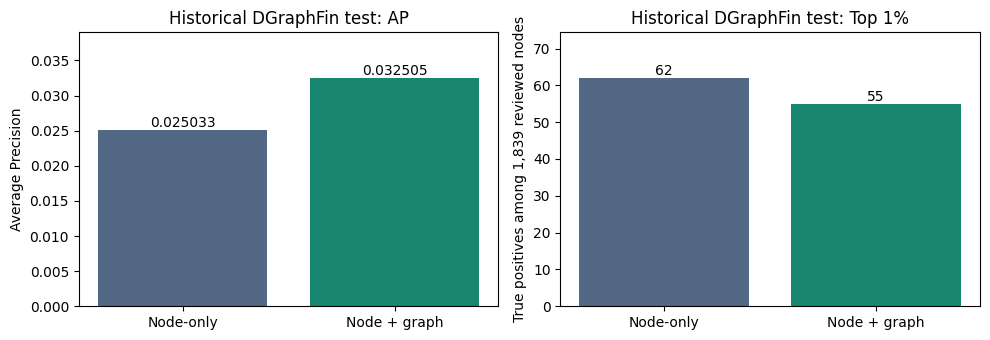

In [4]:
historical = pd.read_csv(PROJECT / 'evidence/historical/rq1_primary_metrics.csv')
display(historical)
assert historical['top_1_percent_positive'].tolist() == [62, 55]
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
names = ['Node-only', 'Node + graph']
colors = ['#526884', '#18856e']
axes[0].bar(names, historical['average_precision'], color=colors)
axes[0].set_ylabel('Average Precision')
axes[0].set_title('Historical DGraphFin test: AP')
axes[1].bar(names, historical['top_1_percent_positive'], color=colors)
axes[1].set_ylabel('True positives among 1,839 reviewed nodes')
axes[1].set_title('Historical DGraphFin test: Top 1%')
for ax, values in zip(axes, [historical['average_precision'], historical['top_1_percent_positive']]):
    for i, value in enumerate(values):
        ax.text(i, value, f'{value:.6f}' if value < 1 else str(int(value)), ha='center', va='bottom')
    ax.margins(y=0.2)
plt.tight_layout()
plt.show()

## 3. Đồng điểm tại ngưỡng K / Ties at the review boundary

Trong hàm đánh giá của KLTN, khi điểm bằng nhau thì ID số nhỏ hơn đứng trước.
Quy tắc rõ ràng giúp tái lập; chưa tự chứng minh cách phá hòa đó tốt cho nghiệp vụ.
The explicit numeric-ID tie rule is reproducible, but needs sensitivity analysis.

In [5]:
from shared_risk_context.evaluation import score_metrics
tie_example = score_metrics(np.array([1, 0, 0]), np.array([0.5, 0.5, 0.1]), np.array([20, 10, 30]))
assert tie_example['top_1_percent_positive'] == 0  # ID 10 wins the score tie.
LAB_RESULT = {'scope': 'synthetic graph checks and historical table inspection',
              'fixture_shape': list(graph_features.shape), 'direction_check': 'PASS',
              'historical_ap': historical['average_precision'].tolist(),
              'historical_top_1_percent_tp': historical['top_1_percent_positive'].tolist(),
              'tie_check': 'PASS', 'new_dataset_training': False}
print(LAB_RESULT)

{'scope': 'synthetic graph checks and historical table inspection', 'fixture_shape': [5, 6], 'direction_check': 'PASS', 'historical_ap': [0.0250325607580735, 0.0325054377836055], 'historical_top_1_percent_tp': [62, 55], 'tie_check': 'PASS', 'new_dataset_training': False}


**Bước tiếp theo / Next research:** ablation hướng vào/ra, phân tích ties và nhiều mức công suất rà soát.
Các thí nghiệm mới phải được ghi riêng với kết quả v2.1 đã khóa.